In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "dataset/processed_weather.csv"
)

print(df.shape)
display(df.head())
df.info()

(1826, 17)


,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,month,day,day_of_week,month_sin,month_cos,target_temperature
0,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,20837.76,6,30,2,1.224647e-16,-1.000000,29.8
1,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,21439.24,7,1,3,-5.000000e-01,-0.866025,29.2
2,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,12291.52,7,2,4,-5.000000e-01,-0.866025,29.2
3,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,29486.65,7,3,5,-5.000000e-01,-0.866025,28.6
4,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,41145.46,7,4,6,-5.000000e-01,-0.866025,28.4


<class 'pandas.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   weather_code                 1826 non-null   int64  
 1   temperature_2m_mean          1826 non-null   float64
 2   temperature_2m_max           1826 non-null   float64
 3   temperature_2m_min           1826 non-null   float64
 4   precipitation_sum            1826 non-null   float64
 5   rain_sum                     1826 non-null   float64
 6   precipitation_hours          1826 non-null   float64
 7   wind_speed_10m_max           1826 non-null   float64
 8   wind_gusts_10m_max           1826 non-null   float64
 9   wind_direction_10m_dominant  1826 non-null   int64  
 10  sunshine_duration            1826 non-null   float64
 11  month                        1826 non-null   int64  
 12  day                          1826 non-null   int64  
 13  day_of_week                  

In [6]:
features = [
    'weather_code',
    'temperature_2m_mean',
    'temperature_2m_max',
    'temperature_2m_min',
    'precipitation_sum',
    'rain_sum',
    'precipitation_hours',
    'wind_speed_10m_max',
    'wind_gusts_10m_max',
    'wind_direction_10m_dominant',
    'sunshine_duration',
    'month',
    'day',
    'day_of_week',
    'month_sin',
    'month_cos'
]

X = df[features]

y = df['target_temperature']

In [7]:
# Weather code is categorical, not continuous
X['weather_code'] = X['weather_code'].astype(str)

# 80% training, 20% testing
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1460
Testing samples: 366


In [8]:
numeric_features = [
    col for col in features
    if col != 'weather_code'
]

categorical_features = ['weather_code']

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [9]:
models = {
    "Dummy Regressor": DummyRegressor(
        strategy='mean'
    ),

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    )
}

In [10]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    predictions = pipeline.predict(X_test)

    # Evaluation
    mae = mean_absolute_error(
        y_test, predictions
    )

    mse = mean_squared_error(
        y_test, predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test, predictions
    )

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = pipeline

    print(f"\n{name}")
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2:", round(r2, 3))


Dummy Regressor
MAE: 3.145
RMSE: 3.831
R2: -0.002

Linear Regression
MAE: 0.709
RMSE: 0.937
R2: 0.94

Decision Tree
MAE: 0.843
RMSE: 1.097
R2: 0.918

Random Forest
MAE: 0.71
RMSE: 0.927
R2: 0.941

Gradient Boosting
MAE: 0.686
RMSE: 0.912
R2: 0.943

Extra Trees
MAE: 0.693
RMSE: 0.903
R2: 0.944

Hist Gradient Boosting
MAE: 0.704
RMSE: 0.928
R2: 0.941


In [11]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE'
).reset_index(drop=True)

display(results_df)

results_df.to_csv(
    "models/model_comparison.csv",
    index=False
)

,Model,MAE,MSE,RMSE,R2 Score
0,Extra Trees,0.692895,0.815683,0.903152,0.944323
1,Gradient Boosting,0.686057,0.832220,0.912261,0.943195
2,Random Forest,0.710390,0.859582,0.927136,0.941327
3,Hist Gradient Boosting,0.703942,0.861272,0.928047,0.941212
4,Linear Regression,0.708929,0.877874,0.936949,0.940078
5,Decision Tree,0.842732,1.203548,1.097064,0.917849
6,Dummy Regressor,3.145232,14.679185,3.831342,-0.001968


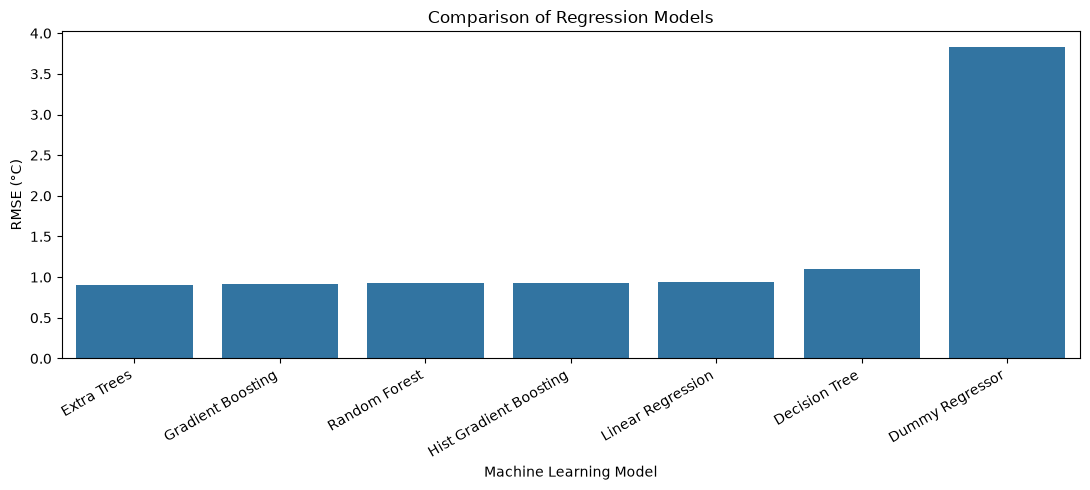

In [14]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("Comparison of Regression Models")
plt.ylabel("RMSE (°C)")
plt.xlabel("Machine Learning Model")

plt.xticks(rotation=30, ha='right')

plt.tight_layout()

plt.savefig("graphs/model_comparison.png")

plt.show()

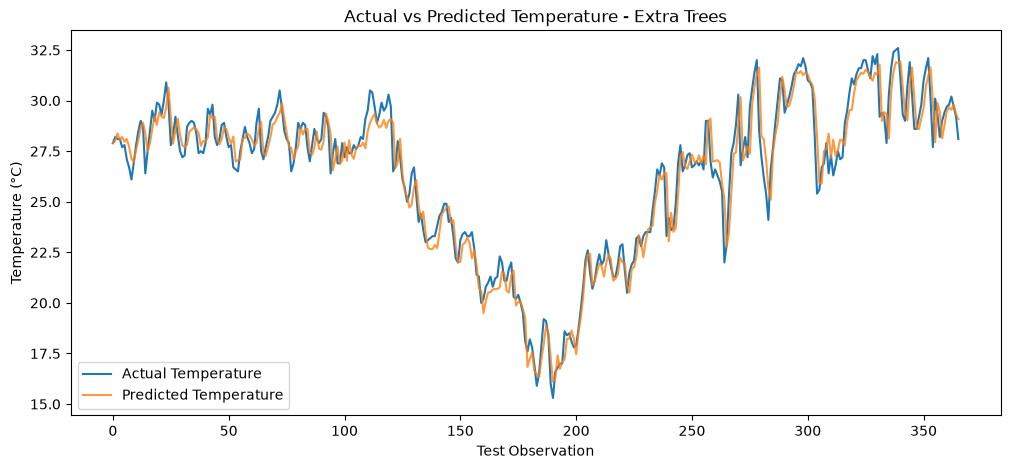

In [15]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values,
    label='Actual Temperature'
)

plt.plot(
    predictions,
    label='Predicted Temperature',
    alpha=0.8
)

plt.title(
    f"Actual vs Predicted Temperature - {best_model_name}"
)

plt.xlabel("Test Observation")
plt.ylabel("Temperature (°C)")

plt.legend()

plt.savefig("graphs/actual_vs_predicted.png")

plt.show()

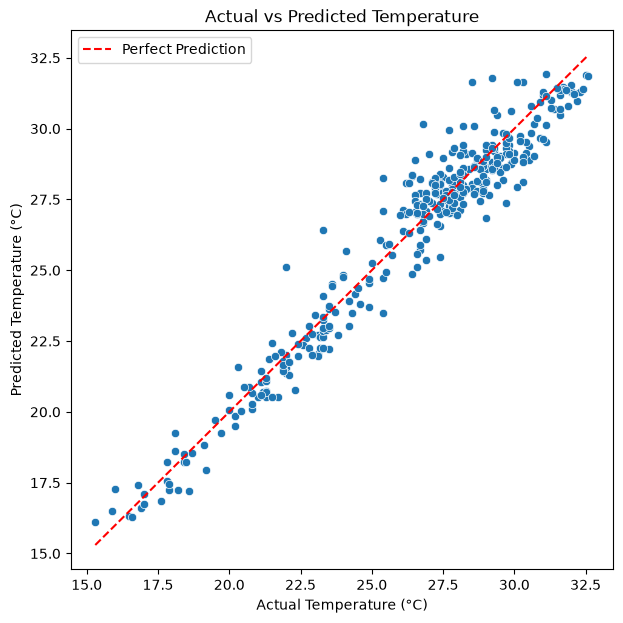

In [16]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    x=y_test,
    y=predictions
)

# Perfect prediction reference line
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")

plt.title("Actual vs Predicted Temperature")

plt.legend()

plt.savefig("graphs/prediction_scatter.png")

plt.show()

In [17]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

joblib.dump(
    best_model,
    "models/best_weather_model.pkl"
)

joblib.dump(
    features,
    "models/feature_columns.pkl"
)

print("Best Model:", best_model_name)
print("Model saved successfully!")

Best Model: Extra Trees
Model saved successfully!
